# The Company a Molecule Keeps

**Local training-vocabulary proxy · MRR@25:** row-random ranks identity lookup above mass (1.000 vs 0.216); molecule-grouped folds reverse the order (0.000 vs 0.212).

Method: score the same 120 molecule identities under two split rules, against the same 275,810-candidate vocabulary.

- Row splits let repeated scans of one identity cross the boundary.
- Grouped folds hold every scan for a molecule together.
- Identity lookup is a leakage diagnostic, not a deployable model.

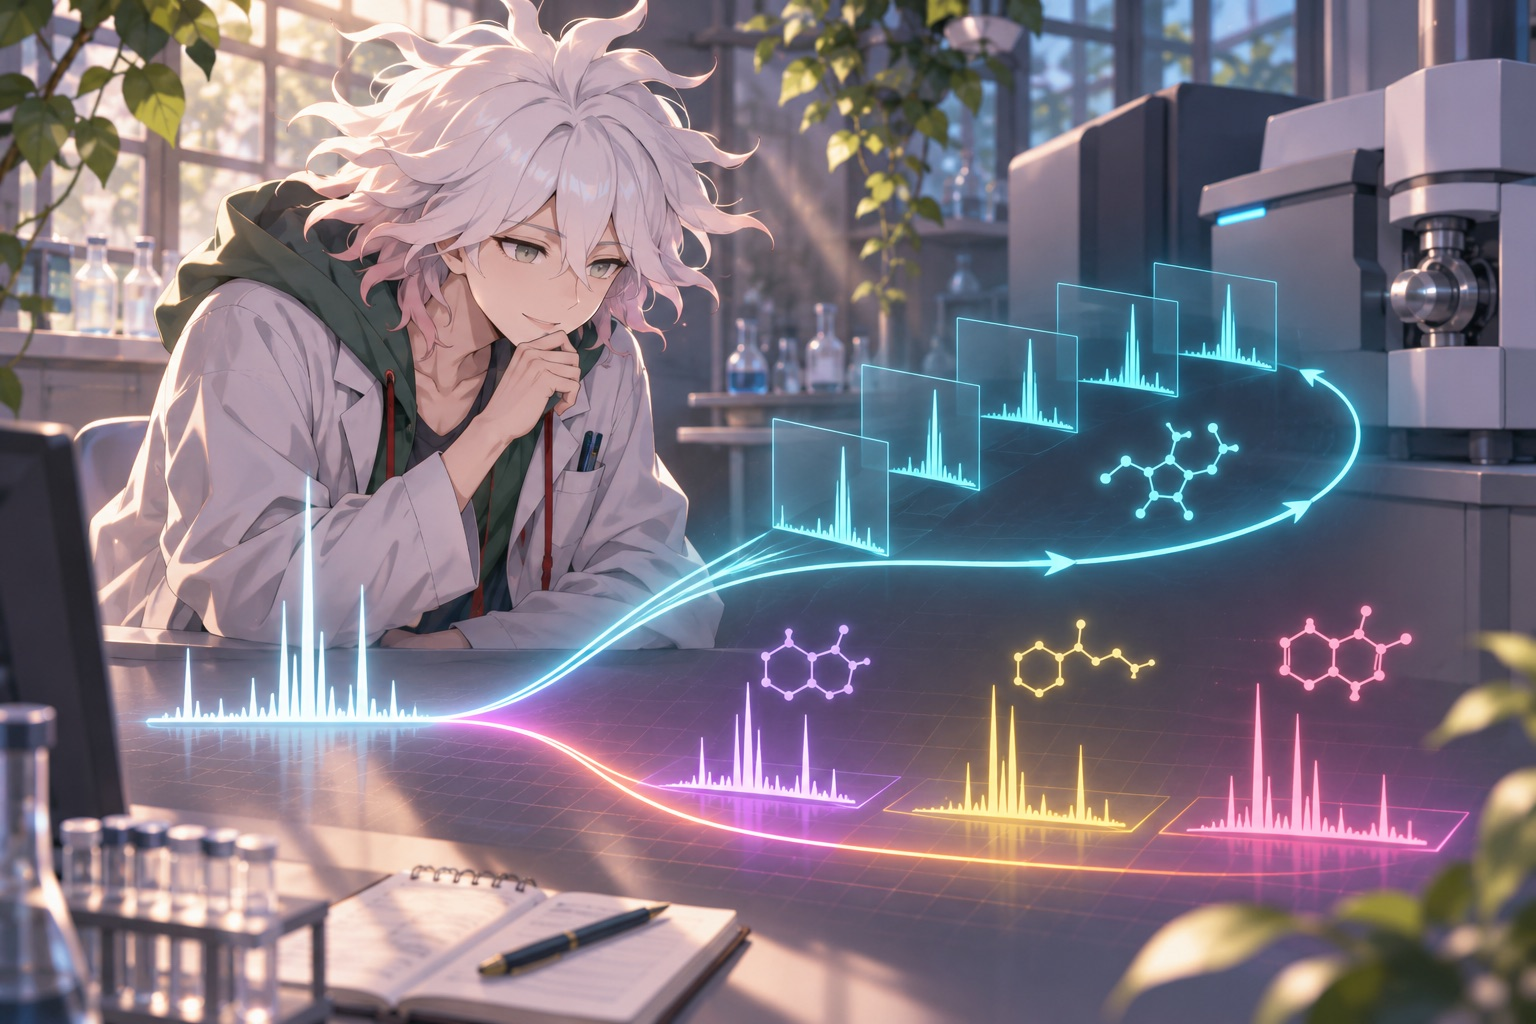

## The question

A spectrum table can contain several scans for one molecule. If rows are split at random, the same InChIKey14 may appear on both sides. A method can look strong by recognizing a familiar identity. Grouped validation asks a harder question: can it rank a molecule whose scans were all withheld?

We use identity lookup as a deliberately simple leak detector. It returns rank 1 only when that exact identity appears among reference rows. It is not a proposed chemistry model.

In [ ]:
from pathlib import Path
import hashlib, json, math, os, platform, time
os.environ['OMP_NUM_THREADS']='2'; os.environ['OPENBLAS_NUM_THREADS']='2'
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize':(9,4.8),'axes.spines.top':False,'axes.spines.right':False,'font.size':11})

def find_train():
    env = os.environ.get('CASMI_TRAIN_PARQUET')
    if env and Path(env).is_file(): return Path(env)
    kaggle_root = Path('/kaggle/input')
    if kaggle_root.exists():
        found = sorted(kaggle_root.rglob('train.parquet'))
        if found: return found[0]
    local = Path('../_shared/data/train.parquet')
    if local.is_file(): return local
    raise FileNotFoundError('Attach the Enveda CASMI26 competition training data; internet is not used.')

DATA_PATH = find_train()
print('Training data:', DATA_PATH)

## Keep identities together

The cohort is fixed before either comparison: first 120 identities with at least two scans under the retained SHA-256 ordering. Both split rules use those same molecules. Candidate masses come from the training file's molecular formulas.

In [ ]:
PROTON=1.007276466621; AMMONIUM=18.033823; WATER=18.010564684
SODIUM=22.989218; POTASSIUM=38.963158; CHLORIDE=34.969402; FORMIC=44.998203
SHIFT={'[M+H]+':-PROTON,'[M+NH4]+':-AMMONIUM,'[M-H2O+H]+':WATER-PROTON,'[M-2H2O+H]+':2*WATER-PROTON,'[M+Na]+':-SODIUM,'[M+K]+':-POTASSIUM,'[M-H]-':PROTON,'[M-H2O-H]-':WATER+PROTON,'[M+CH2O2-H]-':-FORMIC,'[M+Cl]-':-CHLORIDE}
EM={'C':12.0,'H':1.00782503223,'N':14.00307400443,'O':15.99491461957,'P':30.97376199842,'S':31.9720711744,'F':18.99840316273,'Cl':34.968852682,'Br':78.9183376,'I':126.9044719,'Na':22.9897692820,'K':38.9637064864,'Si':27.976926535,'Se':79.9165218,'B':11.00930536}
PREFIX=b'casmi-lead-v20261029\0'; SEED=20261106; N_TARGETS=120
def fmass(formula):
    if not isinstance(formula,str) or not formula: return float('nan')
    i=0; total=0.0
    while i<len(formula):
        if not formula[i].isupper(): return float('nan')
        el=formula[i]; i+=1
        if i<len(formula) and formula[i].islower(): el+=formula[i]; i+=1
        if el not in EM: return float('nan')
        j=i
        while i<len(formula) and formula[i].isdigit(): i+=1
        total += EM[el]*int(formula[j:i] or '1')
    return total
def nmass(mz,adduct):
    shift=SHIFT.get(adduct or '')
    return float(mz+shift) if shift is not None and np.isfinite(mz) and mz>0 else float('nan')
def rr(rank): return 1/rank if rank is not None and rank<=25 else 0.0
def stable_rank(errors, idx):
    v=errors[idx]
    return 1+int(np.count_nonzero(errors<v))+int(np.count_nonzero(errors[:idx]==v))
def mass_rank(query_masses,candidate_masses,idx):
    q=np.asarray([m for m in query_masses if np.isfinite(m)],dtype=float)
    if not len(q): return None
    e=np.zeros(len(candidate_masses))
    for m in q: e += np.abs(candidate_masses-m)/m*1e6
    e /= len(q); e[~np.isfinite(e)]=1e12
    return stable_rank(e,idx)

started=time.monotonic()
table=pq.read_table(DATA_PATH,columns=['inchikey14','molecular_formula','precursor_mz','adduct'])
df=table.to_pandas(); df=df[df.inchikey14.notna()].copy(); df['inchikey14']=df.inchikey14.astype(str)
keys=df.inchikey14.drop_duplicates().tolist()
if len(keys)!=275810: raise ValueError(f'Expected 275810 candidate groups; found {len(keys)}')
counts=df.groupby('inchikey14',sort=False).size()
ordered=sorted((k for k in keys if counts[k]>=2),key=lambda k:(hashlib.sha256(PREFIX+k.encode()).digest(),k))
targets=ordered[:N_TARGETS]; idx={k:i for i,k in enumerate(keys)}
fm=df.drop_duplicates('inchikey14').set_index('inchikey14').molecular_formula.to_dict()
candidate_masses=np.asarray([fmass(fm.get(k)) for k in keys]); candidate_masses[~np.isfinite(candidate_masses)]=1e12
parts={k:g for k,g in df[df.inchikey14.isin(targets)].groupby('inchikey14',sort=False)}
rng=np.random.default_rng(SEED); row_data=[]; random_mass=[]; random_lookup=[]; grouped_mass=[]; grouped_lookup=[]; folds=[]
for k in targets:
    g=parts[k]; order=rng.permutation(len(g)); nref=max(1,min(len(g)-1,len(g)//2)); q=g.iloc[order[nref:]]
    qmass=[nmass(float(m),a) for m,a in zip(q.precursor_mz,q.adduct)]
    r=mass_rank(qmass,candidate_masses,idx[k]); random_mass.append(r); random_lookup.append(1)
    row_data.append({'inchikey14':k,'rows':len(g),'random_mass_rank':r,'random_lookup_rank':1})
for start in range(0,N_TARGETS,40):
    fold=[]
    for k in targets[start:start+40]:
        g=parts[k]; qmass=[nmass(float(m),a) for m,a in zip(g.precursor_mz,g.adduct)]
        r=mass_rank(qmass,candidate_masses,idx[k]); grouped_mass.append(r); grouped_lookup.append(None); fold.append(r)
    folds.append(float(np.mean([rr(r) for r in fold])))
for i,k in enumerate(targets): row_data[i]['grouped_mass_rank']=grouped_mass[i]; row_data[i]['grouped_lookup_rank']=None
per_group=pd.DataFrame(row_data)
score=lambda rs: float(np.mean([rr(r) for r in rs]))
random_folds=[score(per_group.random_mass_rank.iloc[i:i+40].tolist()) for i in range(0,N_TARGETS,40)]
train_hash=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
proof={'status':'complete','train_sha256':train_hash,'rows_scanned':int(table.num_rows),'candidate_groups':len(keys),'target_groups':len(targets),'target_rows_min_median_max':[int(per_group.rows.min()),int(per_group.rows.median()),int(per_group.rows.max())],'seed':SEED,'random_query_rows':int(sum(len(parts[k])-max(1,min(len(parts[k])-1,len(parts[k])//2)) for k in targets)),'grouped_query_rows':int(sum(len(parts[k]) for k in targets)),'random_identity_overlap':len(targets),'grouped_identity_overlap':0,'random_lookup_mrr_at_25':score(random_lookup),'random_mass_mrr_at_25':score(random_mass),'grouped_lookup_mrr_at_25':score(grouped_lookup),'grouped_mass_mrr_at_25':score(grouped_mass),'grouped_fold_mass_mrr_at_25':folds,'random_fold_mass_mrr_at_25':random_folds,'ranking_reversal':score(random_lookup)>score(random_mass) and score(grouped_mass)>score(grouped_lookup),'runtime_seconds':round(time.monotonic()-started,3)}
print(json.dumps(proof,indent=2))
per_group.head()

## Two rankings, one lesson

The row split lets every selected identity appear in reference scans. The grouped folds remove that path. Precursor mass barely moves; the lookup diagnostic collapses because its input identity is gone.

In [ ]:
fig,ax=plt.subplots(figsize=(9,4.6))
labels=['Identity lookup\n(random rows)','Precursor mass\n(random rows)','Identity lookup\n(grouped)','Precursor mass\n(grouped)']
values=[proof['random_lookup_mrr_at_25'],proof['random_mass_mrr_at_25'],proof['grouped_lookup_mrr_at_25'],proof['grouped_mass_mrr_at_25']]
colors=['#ef8354','#4f9da6','#ef8354','#4f9da6']
bars=ax.bar(labels,values,color=colors,width=.65); ax.set_ylim(0,1.08); ax.set_ylabel('Macro MRR@25'); ax.grid(axis='y',alpha=.2)
for b,v in zip(bars,values): ax.text(b.get_x()+b.get_width()/2,v+.025,f'{v:.3f}',ha='center',fontweight='bold')
ax.set_title('The apparent winner depends on the split'); plt.tight_layout(); plt.show()

The method order reverses when the split holds molecule identities together.

In [ ]:
fig,ax=plt.subplots(figsize=(8.5,4.5))
x=np.arange(3); w=.34; fold=np.asarray(proof['grouped_fold_mass_mrr_at_25'])
ax.bar(x-w/2,proof['random_fold_mass_mrr_at_25'],w,label='Row-random mass',color='#4f9da6')
ax.bar(x+w/2,fold,w,label='Grouped mass',color='#f6bd60')
ax.set_xticks(x,['Fold 1','Fold 2','Fold 3']); ax.set_ylabel('Macro MRR@25'); ax.set_ylim(0,max(fold.max(),proof['random_mass_mrr_at_25'])*1.28); ax.legend(frameon=False); ax.grid(axis='y',alpha=.2)
ax.set_title('Mass ranking within the same 40 identities'); plt.tight_layout(); plt.show()

The two bars in each fold use the same 40 molecule identities. The query scans differ: row-random splits scans within each identity, while grouped validation withholds all scans for those identities.

In [ ]:
fig,ax=plt.subplots(figsize=(7.8,5.2))
r=np.asarray([1/x if x and x<=25 else 0 for x in per_group.random_mass_rank])
g=np.asarray([1/x if x and x<=25 else 0 for x in per_group.grouped_mass_rank])
ax.scatter(r,g,s=24,alpha=.62,color='#6c5ce7',edgecolors='white',linewidth=.35); ax.plot([0,1],[0,1],ls='--',color='#888',lw=1)
ax.set(xlim=(-.03,1.03),ylim=(-.03,1.03),xlabel='Random-row mass reciprocal rank',ylabel='Grouped mass reciprocal rank',title='Per-identity mass results stay broadly comparable'); ax.grid(alpha=.18); plt.tight_layout(); plt.show()

Most points stay near the diagonal; the dramatic change comes from whether a method can see the same identity.

In [ ]:
fig,ax=plt.subplots(figsize=(8.8,4.7))
sizes=per_group.rows.to_numpy(); ax.hist(np.log10(sizes),bins=18,color='#00a6a6',edgecolor='white')
ax.set_xlabel('log10 scans per selected molecule'); ax.set_ylabel('Molecule groups'); ax.set_title('Repeated scans create opportunities for identity overlap'); ax.grid(axis='y',alpha=.18); plt.tight_layout(); plt.show()

## Read the result carefully

- Same 120 identities and candidate vocabulary; the query rows differ by split rule.
- Random-row identity lookup is guaranteed to see each identity because every group has at least two scans and one reference row.
- Grouped identity lookup sees none of the held identities, so its score is zero by design.
- The mass method uses only supplied formulas and precursor/adduct masses. This is a local training-vocabulary proxy, not the official leaderboard metric.
- This experiment shows how leakage can change a method ranking. It does not estimate how a real spectral-neighbor model would score.

**Credits:** Enveda and the CASMI26 competition authors for the training data. Credit to [inversion's CASMI denovo tutorial](https://www.kaggle.com/code/inversion/casmi-denovo-tutorial-notebook) for the clear starter-teaching bar; no prose or code is copied.

**What to try next:** replace identity lookup with a chemically meaningful spectral-neighbor ranker, keep its tuning inside training folds, and preserve the molecule-level holdout.